# 第8回 振り返り ― 経営層向けの説明資料を1枚作る

**使い方**：上のセルから順に `Shift + Enter` で実行していきます。
この回は「🧪 実験」のセルで、**資料の文章を自分の言葉に書き換える**のが中心の作業です。

**この回のゴール**

1. 第1回〜第7回で分かったことを、1本の流れとして説明できる
2. 分析結果を「言えること」「方向なら言えること」「言えないこと」に分けられる
3. 専門用語を使わずに、経営層に伝わる言葉と数字に直せる
4. 「MMMで何が分かるか」の説明資料を1枚作る（画像ファイルとして保存）

**所要時間**：60分ほど。重い計算はありません（いちばん長いセルで1分ほど）。

**前提**：第4回で保存した学習結果（`mmm_cs1.nc`）を使います。まだ無いときは、この回の中で学習します（3〜13分）。

> **この資料の位置づけ**：図に使うのは公開されている学習用データの分析結果です。資料は「MMMとはこういうことが分かる手法です」という**説明用の例**で、特定の企業の実績として見せるものではありません。資料の中にもその旨を書きます。

> **この教材について**
>
> - PyMC-Marketing の公式ケーススタディ「[MMM End-to-End Case Study](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_case_study.html)」を、日本語で順に学べるように組み立て直した教材です（作成：Birdwing Technologies合同会社）。
> - コードは本家（Apache License 2.0）をもとに改変しています。解説・図・小課題は独自に加えたものです。
> - データは本家と同じ、公開されている学習用のデータです。
> - 解説ページと全体の目次：<https://bwtech.co.jp/learn/mmm/08-review-onepager>

## 0. 準備

最初のセルは、どの回にも共通の準備です。**Google Colab でも、自分のPCでも、そのまま実行できます。**

- データがなければダウンロードします（約80KB）
- グラフに日本語を表示できるようにします
- Google Colab のときだけ、必要なライブラリを入れます（数分かかります）
- 学習結果の置き場所を決めます（Colab のときは Google ドライブ。初回に許可の画面が出ます）

In [1]:
# ===== 共通の準備（Google Colab でも、自分のPCでも、このまま実行できます） =====
import subprocess, sys, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# --- g++（計算を速くする部品）がない環境では、その旨を PyTensor に伝える（WARNING が短くなる） ---
import os, shutil
if shutil.which("g++") is None:
    os.environ["PYTENSOR_FLAGS"] = "cxx="

# --- Colab のときだけ、ライブラリを入れる（数分かかります） ---
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymc-marketing==0.19.2", "nutpie==0.16.8"], check=True)

# --- ファイルの置き場所 ---
BASE_DIR = Path("/content/mmm-pymc") if IN_COLAB else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "case_study_data.csv"

# --- 学習結果の置き場所 ---
# Colab は接続が切れるとファイルが消えるので、学習結果は Google ドライブに置く（初回に許可の画面が出ます）。
# ドライブを使いたくないときは USE_DRIVE = False にする（その場合は、回ごとに学習し直します）。
USE_DRIVE = True
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    MODEL_DIR = Path("/content/drive/MyDrive/mmm-pymc/models")
else:
    MODEL_DIR = BASE_DIR / "models"
MODEL_PATH = MODEL_DIR / "mmm_cs1.nc"

# --- 作った資料の保存先 ---
OUT_DIR = BASE_DIR / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- データの取得（なければダウンロードする） ---
DATA_URL = "https://raw.githubusercontent.com/pymc-labs/pymc-marketing/0.19.2/data/case_study_data.csv"
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

# --- グラフの日本語フォント ---
import matplotlib.pyplot as plt
from matplotlib import font_manager

def setup_japanese_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["Meiryo", "Yu Gothic", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "IPAGothic"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            return name
    # 日本語フォントが見つからないとき（Colab など）は、フォント入りのパッケージを入れる
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=True)
    import matplotlib_fontja  # 読み込むだけで日本語フォント（IPAexGothic）が設定される
    return "IPAexGothic"

font_name = setup_japanese_font()
plt.rcParams["axes.unicode_minus"] = False    # マイナス記号の文字化けを防ぐ

print("実行環境:", "Google Colab" if IN_COLAB else "自分のPC")
print("データ:", DATA_PATH.relative_to(BASE_DIR).as_posix(), "（取得済み）")
print("日本語フォント:", font_name)

実行環境: 自分のPC
データ: data/case_study_data.csv （取得済み）
日本語フォント: Meiryo


この回で使うライブラリを読み込みます。

In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from scipy.optimize import minimize

from pymc_marketing.mmm.multidimensional import MMM

SEED = 42
FAST = {"mode": "NUMBA"}


WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


### 学習結果を読み込む

第4回で保存した学習結果（`mmm_cs1.nc`）を読み込みます。

- 見つかったとき → 読み込むだけ（数秒）
- 見つからないとき → 第4回と同じ設定で、この場で学習して保存します（**3〜13分**）

In [3]:
def load_or_fit_model():
    """学習結果を読み込む。なければ、第4回と同じ設定で学習して保存する。"""
    if MODEL_PATH.exists():
        print("保存済みの学習結果を読み込みました:", MODEL_PATH.name)
        return MMM.load(str(MODEL_PATH))

    print("学習結果が見つからないので、第4回と同じ設定で学習します（3〜13分）。")
    from pymc_extras.prior import Prior
    from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation

    raw = pd.read_csv(DATA_PATH, parse_dates=["wk_strt_dt"])
    names = {
        "mdsp_dm": "DM", "mdsp_inst": "折込", "mdsp_nsp": "新聞", "mdsp_audtr": "ラジオ",
        "mdsp_vidtr": "TV", "mdsp_so": "ソーシャル", "mdsp_on": "ディスプレイ",
    }
    channels = list(names.values())
    controls = [c for c in raw.columns if c.startswith("hldy_")]
    data = raw[["wk_strt_dt", "sales", *names.keys(), *controls]].rename(columns=names)
    train = data[data["wk_strt_dt"] <= pd.to_datetime("2018-02-01")]
    X_tr, y_tr = train.drop(columns="sales"), train["sales"]
    share = X_tr[channels].sum() / X_tr[channels].sum().sum()

    model = MMM(
        model_config={
            "intercept": Prior("Normal", mu=0.2, sigma=0.05),
            "saturation_beta": Prior("HalfNormal", sigma=share[channels].to_numpy(), dims="channel"),
            "gamma_control": Prior("Normal", mu=0, sigma=1, dims="control"),
            "gamma_fourier": Prior("Laplace", mu=0, b=1, dims="fourier_mode"),
            "likelihood": Prior("TruncatedNormal", lower=0, sigma=Prior("HalfNormal", sigma=1)),
        },
        date_column="wk_strt_dt", target_column="sales",
        channel_columns=channels, control_columns=controls,
        adstock=GeometricAdstock(l_max=6), saturation=LogisticSaturation(), yearly_seasonality=5,
    )
    model.build_model(X_tr, y_tr)
    model.add_original_scale_contribution_variable(
        var=["channel_contribution", "control_contribution", "intercept_contribution",
             "yearly_seasonality_contribution", "y"]
    )
    model.fit(X_tr, y_tr, chains=4, tune=1_000, draws=1_000, target_accept=0.9,
              nuts_sampler="nutpie", random_seed=42)
    model.sample_posterior_predictive(X_tr, extend_idata=True, combined=True, random_seed=42,
                                      compile_kwargs={"mode": "NUMBA"})
    for group in ["warmup_posterior", "warmup_sample_stats"]:
        if group in model.idata.groups():
            del model.idata[group]
    MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    model.save(str(MODEL_PATH))
    return model

mmm = load_or_fit_model()
posterior = mmm.idata["posterior"]
const = mmm.idata["constant_data"]


保存済みの学習結果を読み込みました: mmm_cs1.nc


In [4]:
raw_df = pd.read_csv(DATA_PATH, parse_dates=["wk_strt_dt"])

channel_names = {
    "mdsp_dm": "DM", "mdsp_inst": "折込", "mdsp_nsp": "新聞", "mdsp_audtr": "ラジオ",
    "mdsp_vidtr": "TV", "mdsp_so": "ソーシャル", "mdsp_on": "ディスプレイ",
}
channels = list(channel_names.values())
control_columns = [c for c in raw_df.columns if c.startswith("hldy_")]
date_column, target_column = "wk_strt_dt", "sales"

data_df = raw_df[[date_column, target_column, *channel_names.keys(), *control_columns]].rename(columns=channel_names)
split_date = pd.to_datetime("2018-02-01")
train_df = data_df[data_df[date_column] <= split_date]
test_df = data_df[data_df[date_column] > split_date]
X_train = train_df.drop(columns=target_column)
print(f"学習用: {len(train_df)} 週 / テスト用: {len(test_df)} 週")

学習用: 183 週 / テスト用: 26 週


## 1. 全体の振り返り

### 1-1. 1つの式で振り返る

この教材で作ったモデルは、結局のところ次の1つの式です。

$$
\text{売上}_t \;=\; \underbrace{\text{ベース}}_{\text{広告がなくても売れる分}}
\;+\; \underbrace{\sum_{c} \beta_c \cdot S\big(\lambda_c \cdot \text{adstock}(x_{c,t};\,\alpha_c)\big)}_{\text{広告（7チャネル）の上乗せ}}
\;+\; \underbrace{\text{祝日}_t + \text{季節}_t}_{\text{広告以外の上下}}
\;+\; \text{誤差}_t
$$

各回は、この式のどこかを扱っていました。

| 回 | テーマ | 式のどの部分か | いちばん大事な学び |
|---|---|---|---|
| 1 | データ理解 | 式を作る前 | 相関では広告効果は測れない。TV と売上の相関 0.66 は、年末を除くと 0.20 に下がった |
| 2 | adstock と saturation | $\text{adstock}$ と $S$ | 広告は「後まで残る」「出しすぎると鈍る」。比べるべきは平均ではなく限界効果 |
| 3 | モデル定義と事前分布 | $\beta, \alpha, \lambda$ などの「分析前の想定」 | 想定だけでどんな売上が出るかを先に確かめる（事前予測チェック） |
| 4 | 推定と診断 | 式全体をデータに合わせる | 計算が正しく終わったか（divergence、R-hat、ESS）と、データが想定をどれだけ動かしたか |
| 5 | 結果の解釈 | 広告の項をチャネル別に読む | 貢献・ROAS は幅つきで読む。上位3チャネルの順位は決められなかった |
| 6 | 予測精度の検証 | 式全体を、見ていない期間で試す | 半年の合計はよく当たる。週ごとの予測は「前年同週」と同程度 |
| 7 | 予算最適化 | 広告の項を最大にする $x$ を探す | 限界ROASをそろえる。確かな部分だけを、小さく動かす |

### 1-2. 学びを3つにしぼると

1. **MMMは「分ける」道具**。売上を、広告がなくても売れた分と、広告が上乗せした分に分ける。予測を当てる道具ではない
2. **答えは必ず幅つき**。幅が広いところは「分かっていない」ということで、それ自体が大事な結果
3. **分析は入口**。最後は小さく試して確かめる（実験）。分析と実験を繰り返して、少しずつ確かにしていく

この3つは、あとで作る資料の骨組みになります。

## 2. 材料の数字をそろえる

資料に使う数字を、保存してある学習結果から計算し直します。計算の中身は第5回・第7回と同じです。

### 2-1. 売上の分解と、チャネル別の割合

In [5]:
S = ("chain", "draw")

channel_contrib = posterior["channel_contribution_original_scale"]            # 4,000組 × 183週 × 7チャネル
base_contrib = posterior["intercept_contribution_original_scale"]
control_contrib = posterior["control_contribution_original_scale"]
season_contrib = posterior["yearly_seasonality_contribution_original_scale"]

spend = const["channel_data"].sel(channel=channels)       # 183週 × 7チャネル
sales = const["target_data"]
dates = pd.to_datetime(sales["date"].values)
n_weeks = len(dates)
total_sales = float(sales.sum())

def rng3(x):
    # 4,000個の答えを「下端（3%）・中央値・上端（97%）」にまとめる
    return np.quantile(np.asarray(x).ravel(), [0.03, 0.5, 0.97])

# 広告の上乗せが、売上に占める割合
media_share = (channel_contrib.sum(dim=("date", "channel")) / total_sales * 100).to_numpy().ravel()
lo, mid, hi = rng3(media_share)
print(f"広告の上乗せが売上に占める割合：中央値 {mid:.0f}%（{lo:.0f}〜{hi:.0f}%）")

# チャネル別：費用の割合と、広告の貢献に占める割合
contrib_total = channel_contrib.sum(dim="date").sel(channel=channels).stack(s=S).transpose("s", "channel").to_numpy()   # 4,000 × 7
contrib_share = contrib_total / contrib_total.sum(axis=1, keepdims=True) * 100
spend_total = spend.sum(dim="date").to_numpy()
spend_share = spend_total / spend_total.sum() * 100

share_table = pd.DataFrame({
    "費用の割合 %": spend_share,
    "貢献の割合 % 下端": np.quantile(contrib_share, 0.03, axis=0),
    "貢献の割合 % 中央値": np.quantile(contrib_share, 0.5, axis=0),
    "貢献の割合 % 上端": np.quantile(contrib_share, 0.97, axis=0),
}, index=channels).sort_values("費用の割合 %", ascending=False)
share_table.round(1)

広告の上乗せが売上に占める割合：中央値 37%（22〜57%）


,費用の割合 %,貢献の割合 % 下端,貢献の割合 % 中央値,貢献の割合 % 上端
DM,45.0,0.7,13.4,45.2
新聞,16.3,0.6,9.4,27.0
ディスプレイ,11.9,2.2,24.4,55.6
TV,10.0,1.5,18.4,46.4
ラジオ,6.8,0.4,7.8,30.2
ソーシャル,5.2,0.3,5.2,18.4
折込,4.8,0.6,9.5,32.7


**確認**　第5回と同じ数字になっているはずです（広告の上乗せ：約37%、範囲は約22〜57%。DM：費用の45%に対して、貢献の中央値は約13%）。

### 2-2. 配分を見直したときの試算

第7回と同じ計算です。テスト期間の週平均を出発点に、総額はそのまま、各チャネル±50%の範囲で最適な配分を求めます。
その倍率を学習期間の183週に当てはめて、「この配分だったら売上はどうなっていたか」を出します。

このセルは1分ほどかかります。

In [6]:
beta = posterior["saturation_beta"].sel(channel=channels).stack(s=S).transpose("s", "channel").to_numpy()   # 4,000 × 7
lam = posterior["saturation_lam"].sel(channel=channels).stack(s=S).transpose("s", "channel").to_numpy()
channel_scale = const["channel_scale"].sel(channel=channels).to_numpy()
target_scale = float(const["target_scale"].values[0])

def weekly_contribution(x):
    u = lam * np.asarray(x) / channel_scale
    return beta * (1 - np.exp(-u)) / (1 + np.exp(-u)) * target_scale

def marginal_roas(x):
    u = lam * np.asarray(x) / channel_scale
    return beta * lam / channel_scale * 2 * np.exp(-u) / (1 + np.exp(-u)) ** 2 * target_scale

def optimize_budget(x_start, flex):
    budget = x_start.sum()
    result = minimize(
        lambda x: -weekly_contribution(x).sum(axis=1).mean() / 1e6,
        x0=x_start, method="SLSQP",
        bounds=[((1 - flex) * v, (1 + flex) * v) for v in x_start],
        constraints=[{"type": "eq", "fun": lambda x: (x.sum() - budget) / budget}],
        options={"ftol": 1e-10, "maxiter": 1000},
    )
    assert result.success, result.message
    return result.x

x_now = test_df[channels].mean().to_numpy()
multiplier = optimize_budget(x_now, 0.5) / x_now

X_train_opt = X_train.copy()
X_train_opt[channels] = X_train[channels] * multiplier
X_train_opt[channels] *= X_train[channels].sum().sum() / X_train_opt[channels].sum().sum()     # 総額をそろえる

def predict(X, seed):
    return mmm.sample_posterior_predictive(
        X, var_names=["y", "channel_contribution"], extend_idata=False, combined=False,
        random_seed=seed, compile_kwargs=FAST, progressbar=False,
    )

pred_now = predict(X_train, SEED)
pred_opt = predict(X_train_opt, SEED + 1)
uplift_sales = (pred_opt["y"].sum(dim="date").to_numpy().ravel() / pred_now["y"].sum(dim="date").to_numpy().ravel() - 1) * 100

lo, mid, hi = rng3(uplift_sales)
print("倍率：", dict(zip(channels, multiplier.round(2))))
print(f"売上全体の増加率：平均 {uplift_sales.mean():+.1f}%、中央値 {mid:+.1f}%（{lo:+.1f}〜{hi:+.1f}%）")
print(f"売上が増える確率：{(uplift_sales > 0).mean():.0%}")

Sampling: [y]


Sampling: [y]


倍率： {'DM': np.float64(0.5), '折込': np.float64(1.5), '新聞': np.float64(0.5), 'ラジオ': np.float64(1.35), 'TV': np.float64(1.5), 'ソーシャル': np.float64(0.98), 'ディスプレイ': np.float64(1.5)}
売上全体の増加率：平均 +9.4%、中央値 +9.3%（-1.4〜+20.4%）
売上が増える確率：95%


**確認**　第7回と同じ結果です（売上全体 平均 約+9%、範囲は 約−1〜+20%、増える確率 約95%）。

## 3. 言えること・言えないことを分ける

経営層向けの資料でいちばん大切なのは、**確かなことと、そうでないことを混ぜない**ことです。

ベイズ推定のよいところは、「この主張が正しい確率」を4,000組のサンプルから直接数えられることです。
いくつかの主張について、確率を出してみます。

In [7]:
roas = contrib_total / spend_total                       # 4,000 × 7（広告費1あたりの売上）
mroas_now = marginal_roas(x_now)                         # 4,000 × 7（いまの配分での限界ROAS）
ix = {c: i for i, c in enumerate(channels)}
top3 = ["ディスプレイ", "折込", "TV"]

claims = {
    "広告の上乗せは、売上の2割を超えている": (media_share > 20).mean(),
    "DM は、費用の割合ほどには貢献していない": (contrib_share[:, ix["DM"]] < spend_share[ix["DM"]]).mean(),
    "DM の ROAS は、7チャネルの中で最も低い": (roas.argmin(axis=1) == ix["DM"]).mean(),
    "配分を見直すと、売上は増える": (uplift_sales > 0).mean(),
    "TV は DM より、追加の広告費が効く（限界ROAS）": (mroas_now[:, ix["TV"]] > mroas_now[:, ix["DM"]]).mean(),
    "折込は DM より、追加の広告費が効く（限界ROAS）": (mroas_now[:, ix["折込"]] > mroas_now[:, ix["DM"]]).mean(),
    "ディスプレイは DM より、追加の広告費が効く（限界ROAS）": (mroas_now[:, ix["ディスプレイ"]] > mroas_now[:, ix["DM"]]).mean(),
    "ROAS が最も高いのはディスプレイである": (roas.argmax(axis=1) == ix["ディスプレイ"]).mean(),
    "ROAS が最も高いのは折込である": (roas.argmax(axis=1) == ix["折込"]).mean(),
    "ROAS が最も高いのは TV である": (roas.argmax(axis=1) == ix["TV"]).mean(),
    "ラジオの ROAS は、ソーシャルより高い": (roas[:, ix["ラジオ"]] > roas[:, ix["ソーシャル"]]).mean(),
}

def label(p):
    if p >= 0.9:
        return "① 言える"
    if p >= 0.7:
        return "② 方向なら言える"
    return "③ 言えない"

claim_table = pd.DataFrame({"モデルから見た確率": pd.Series(claims)})
claim_table["区分"] = claim_table["モデルから見た確率"].map(label)
claim_table.sort_values("モデルから見た確率", ascending=False).round(2)

,モデルから見た確率,区分
広告の上乗せは、売上の2割を超えている,0.98,① 言える
DM は、費用の割合ほどには貢献していない,0.97,① 言える
配分を見直すと、売上は増える,0.95,① 言える
TV は DM より、追加の広告費が効く（限界ROAS）,0.91,① 言える
折込は DM より、追加の広告費が効く（限界ROAS）,0.90,① 言える
ディスプレイは DM より、追加の広告費が効く（限界ROAS）,0.89,② 方向なら言える
ラジオの ROAS は、ソーシャルより高い,0.54,③ 言えない
DM の ROAS は、7チャネルの中で最も低い,0.46,③ 言えない
ROAS が最も高いのは折込である,0.31,③ 言えない
ROAS が最も高いのはディスプレイである,0.29,③ 言えない


**読み方**

区分の線引き（90%以上、70%以上）は、この教材での目安です。決まった基準があるわけではありません。

**① 言える（90%以上）**

- 広告の上乗せは、売上の2割を超えている（約98%）
- DM は、費用の割合（45%）ほどには貢献していない（約97%）
- 総額を変えずに配分を見直すと、売上は増える（約95%）
- TV・折込は、DM より追加の広告費が効く（約90%）。ディスプレイも約89%で、ほぼ同じです

**③ 言えない（70%未満）**

- **どのチャネルの ROAS が一番高いか**。折込 約31%、ディスプレイ 約29%、TV 約22%で、どれも決め手がありません
- DM の ROAS が7チャネルで最下位かどうか（約46%）。「低いほう」とは言えても、「最下位」とは言えません
- ラジオとソーシャルのどちらが上か（約54%。五分五分）

**大事な点**

- 「**一番はどれか**」は言えないのに、「**DM からほかへ移すと増える**」は言える。順位が決まらなくても、動かす方向は決められます。提案に必要なのは後者です
- この確率は「**モデルの仮定が正しければ**」の確率です。モデルに入っていない要因（値引き、競合など）や、仮定の誤りは含まれていません。実際の確かさは、これより低いと考えておきます。だから最後は実験で確かめます

## 4. 経営層の言葉に直す

### 4-1. 用語の言い換え

資料や説明の場では、専門用語をそのまま使いません。この教材で出てきた言葉を、次のように言い換えます。

| 専門用語 | 経営層への言い方 |
|---|---|
| MMM | 売上を「広告がなくても売れた分」と「広告が上乗せした分」に分ける分析 |
| ベース | 広告がなくても売れる分 |
| 貢献 | 広告が上乗せした売上 |
| ROAS | 広告費1円あたりの売上 |
| 限界ROAS | いまより1万円多く出したときに、増える売上 |
| adstock | 広告の効き目が、翌週以降にも残ること |
| saturation（飽和） | 出しすぎると、効きが鈍くなること |
| 交絡 | 売上も広告費も同じ時期に増えるので、関係があるように見えてしまうこと |
| 事前分布 | 分析を始める前の想定 |
| 94%の範囲 | 「〜から〜の間と見ています」 |
| 予算最適化 | 同じ予算で、売上がいちばん増えそうな配分を探すこと |
| アウトオブサンプル検証 | 分析に使っていない期間での答え合わせ |

### 4-2. 数字の伝え方

1. **丸める**。「36.8%」ではなく「約4割」。細かい数字は、実際以上に正確に見えます
2. **幅を必ず添える**。「約4割。ただし2割から6割の間と見ています」
3. **確率は回数で言う**。「95%」より「20回に19回」のほうが伝わる場面があります
4. **絶対額より、比較と方向**。「ROAS は 45 です」より「DM は、ほかの広告より費用に見合っていない可能性が高い」
5. **分からないことは、分からないと書く**。「上位3つの順位は、今回のデータでは決められませんでした」

> **4 についての補足**：このデータは通貨や単位の説明がなく、ROAS の絶対値（40以上）は確かめようがありません。
> 実際の仕事でも、MMMの ROAS は実験で確かめるまでは「チャネル間の比較」として使うほうが安全です。

## 5. 資料の設計

### 5-1. 経営層が知りたいこと

経営層が1枚の資料から知りたいのは、手法の説明ではなく、次の3つです。

| 知りたいこと | 資料のどこで答えるか |
|---|---|
| **何が分かるのか** | 図3つ（売上の内訳／広告ごとの費用対効果／配分を変えたら） |
| **どれくらい信じてよいのか** | 図の幅と、「ご注意」 |
| **自社でやるには、何が必要か** | 「必要なもの」と「進め方」 |

### 5-2. 構成

```
┌──────────────────────────────────────────────┐
│ タイトル（問いの形で）                              │
├──────────────────────────────────────────────┤
│ MMMとは（1〜2行）                                 │
├──────────────┬──────────────┬────────────────┤
│ ① 売上の内訳    │ ② 広告ごとの    │ ③ 配分を変えたら   │
│   （図）       │   費用対効果（図）│   （図）          │
│   ひとこと     │   ひとこと      │   ひとこと        │
├──────────────┼──────────────┼────────────────┤
│ 必要なもの      │ 進め方         │ ご注意           │
├──────────────┴──────────────┴────────────────┤
│ ※ 学習用データでの例であること                        │
└──────────────────────────────────────────────┘
```

**図の選び方**

- **①** は時系列の積み上げ。「灰色＝広告がなくても売れた分、青＝広告の上乗せ」と色だけで伝わります
- **②** は ROAS ではなく「費用の割合」と「貢献の割合」を並べます。単位の問題がなく、「お金をかけている割に…」がひと目で分かります
- **③** は増加率の分布。「増える可能性が高いが、幅がある」が形で伝わります

## 6. 資料を作る

### 6-1. 文章を決める

資料に載せる文章は、すべて次のセルの `TEXT` にまとめてあります。まずはこのまま実行してください（あとの「🧪 実験」で書き換えます）。

- 改行したい場所に `\n` を入れます（自動では折り返しません）
- 数字は、2章・3章の結果を丸めたものです

In [8]:
TEXT = {
    "title": "広告費は、売上にどれだけ効いているのか",
    "subtitle": "MMM（マーケティング・ミックス・モデリング）で分かること",
    "what": "MMMは、過去の売上と広告費の記録から、売上を「広告がなくても売れた分」と「広告が上乗せした分」に分ける統計手法です。\n結果は、確かさの幅と一緒にお出しします。",

    "q1": "① 売上のうち、広告の分はどれだけか",
    "a1": "広告の上乗せは、売上の約4割。\nただし幅があり、2割〜6割の間と見ています。\n年末の山の多くは、季節によるものでした。",

    "q2": "② どの広告が、費用に見合っているか",
    "a2": "DMは費用の45%を占めますが、貢献の中心は\n1割強（幅は1〜45%）。費用に見合わない\n可能性が高い。順位までは決められません。",

    "q3": "③ 同じ予算で、配分を変えるとどうなるか",
    "a3": "総額はそのままで配分を見直した場合の試算。\n売上が増える見込みは、20回に19回。\n増え幅の中心は約1割（ほぼ0〜2割）です。",

    "need_title": "必要なもの",
    "need": "・週ごとの売上（2年分以上が目安）\n・広告の種類ごとの、週ごとの費用\n・セール、値上げ、祝日などの記録",

    "step_title": "進め方",
    "step": "1. データの確認（分析できるかを診断）\n2. 分析と報告（幅つきの結果）\n3. 配分を小さく変えて、結果を確かめる\n4. 半年ごとに分析を更新",

    "note_title": "ご注意",
    "note": "・結果は推定です。幅の広い部分は、\n　まだ分かっていない部分です\n・記録のない要因（競合、天候など）は\n　考慮できません\n・大きな変更の前に、小さく試して確かめます",

    "footer": "※ 図は、公開されている学習用データを分析した例です。特定の企業の実績ではありません。",
    "credit": "Birdwing Technologies",   # 自分の会社名に書き換える
}

### 6-2. 1枚に組み立てる

次のセルは、A4横1枚の資料を描く関数です。長いですが、やっていることは「場所を決めて、図と文字を置く」だけです。

- `fig.add_axes([左, 下, 幅, 高さ])`：紙の中の場所を 0〜1 の割合で指定して、図の枠を作る
- `fig.text(左, 下, 文字)`：紙の中の場所を指定して、文字を置く

保存しました: outputs/mmm_onepager.png


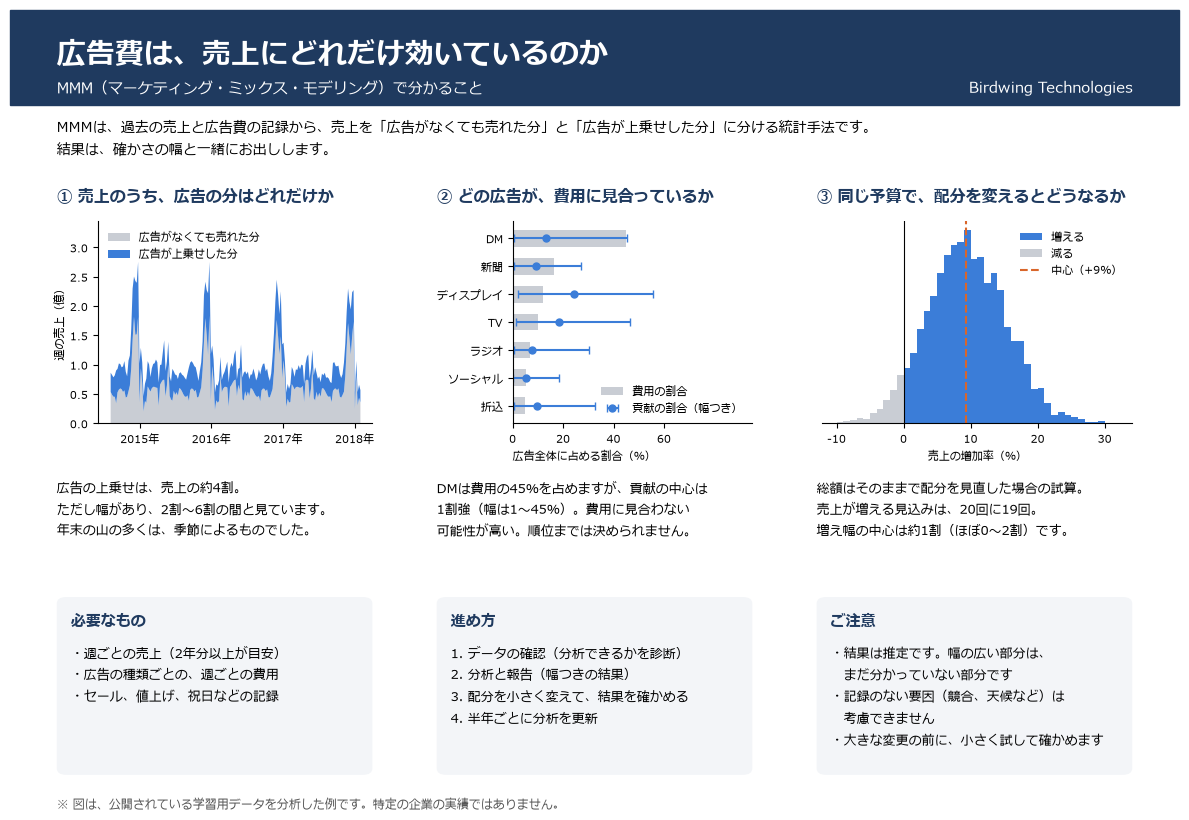

In [9]:
NAVY, BLUE, GRAY, LIGHT, ORANGE = "#1f3a5f", "#3b7dd8", "#c9cdd4", "#f3f5f8", "#d9662b"

def clean(ax):
    # 図の枠線を減らして、すっきり見せる
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(labelsize=8)

def draw_decomposition(ax):
    # ① 売上の内訳（4,000組の平均）
    base_line = np.full(n_weeks, float(base_contrib.mean()))
    other = (season_contrib.mean(dim=S) + control_contrib.sum(dim="control").mean(dim=S)).to_numpy()
    media = channel_contrib.sum(dim="channel").mean(dim=S).to_numpy()
    without_ads = (base_line + other) / 1e8
    with_ads = (base_line + other + media) / 1e8
    ax.fill_between(dates, 0, without_ads, color=GRAY, linewidth=0, label="広告がなくても売れた分")
    ax.fill_between(dates, without_ads, with_ads, color=BLUE, linewidth=0, label="広告が上乗せした分")
    ax.set_ylim(0, with_ads.max() * 1.25)
    ax.set_ylabel("週の売上（億）", fontsize=8)
    ax.xaxis.set_major_locator(plt.matplotlib.dates.YearLocator())
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%Y年"))
    ax.legend(loc="upper left", fontsize=8, frameon=False, ncol=1)
    clean(ax)

def draw_share(ax):
    # ② 費用の割合（灰色の棒）と、貢献の割合（青い丸と幅）
    t = share_table.iloc[::-1]
    y = np.arange(len(t))
    ax.barh(y, t["費用の割合 %"], color=GRAY, height=0.6, label="費用の割合")
    ax.errorbar(t["貢献の割合 % 中央値"], y,
                xerr=[t["貢献の割合 % 中央値"] - t["貢献の割合 % 下端"], t["貢献の割合 % 上端"] - t["貢献の割合 % 中央値"]],
                fmt="o", color=BLUE, capsize=3, markersize=5, linewidth=1.5, label="貢献の割合（幅つき）")
    ax.set_yticks(y)
    ax.set_yticklabels(t.index, fontsize=8.5)
    ax.set_xlim(0, 95)                                # 右に凡例の場所を空ける
    ax.set_xticks([0, 20, 40, 60])
    ax.set_xlabel("広告全体に占める割合（%）", fontsize=8, loc="left")
    ax.legend(loc="lower right", fontsize=8, frameon=False)
    clean(ax)

def draw_uplift(ax):
    # ③ 配分を見直したときの、売上の増加率の分布
    bins = np.arange(np.floor(uplift_sales.min()), np.ceil(uplift_sales.max()) + 1, 1.0)
    ax.hist(uplift_sales[uplift_sales >= 0], bins=bins, color=BLUE, label="増える")
    ax.hist(uplift_sales[uplift_sales < 0], bins=bins, color=GRAY, label="減る")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.axvline(np.median(uplift_sales), color=ORANGE, linewidth=1.5, linestyle="--", label=f"中心（{np.median(uplift_sales):+.0f}%）")
    ax.set_xlabel("売上の増加率（%）", fontsize=8)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.legend(loc="upper right", fontsize=8, frameon=False)
    clean(ax)

def make_onepager(T, path=None):
    fig = plt.figure(figsize=(11.69, 8.27))          # A4 横（インチ）
    fig.patch.set_facecolor("white")

    # タイトルの帯
    fig.add_artist(Rectangle((0, 0.885), 1, 0.115, transform=fig.transFigure, color=NAVY))
    fig.text(0.04, 0.948, T["title"], fontsize=21, fontweight="bold", color="white", va="center")
    fig.text(0.04, 0.906, T["subtitle"], fontsize=11, color="white", va="center")
    fig.text(0.96, 0.906, T["credit"], fontsize=11, color="white", va="center", ha="right")

    # MMMとは
    fig.text(0.04, 0.845, T["what"], fontsize=10, va="center", linespacing=1.6)

    # 図3つ
    left, width = [0.04, 0.365, 0.69], 0.27
    drawers = [draw_decomposition, draw_share, draw_uplift]
    pads = [0.035, 0.065, 0.005]                     # 軸ラベルのぶん、図を右に寄せる量
    for i, (x, draw, pad) in enumerate(zip(left, drawers, pads), start=1):
        fig.text(x, 0.775, T[f"q{i}"], fontsize=11.5, fontweight="bold", color=NAVY, va="center")
        ax = fig.add_axes([x + pad, 0.50, width - pad, 0.245])
        draw(ax)
        fig.text(x, 0.435, T[f"a{i}"], fontsize=9.5, va="top", linespacing=1.6)

    # 下の3つの箱
    for x, key in zip(left, ["need", "step", "note"]):
        fig.add_artist(FancyBboxPatch((x, 0.075), width, 0.215, boxstyle="round,pad=0,rounding_size=0.008",
                                      transform=fig.transFigure, facecolor=LIGHT, edgecolor="none"))
        fig.text(x + 0.012, 0.262, T[f"{key}_title"], fontsize=11, fontweight="bold", color=NAVY, va="center")
        fig.text(x + 0.012, 0.236, T[key], fontsize=9.5, va="top", linespacing=1.65)

    # 注記
    fig.text(0.04, 0.04, T["footer"], fontsize=8.5, color="#555555", va="center")

    if path is not None:
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=200)
        print("保存しました:", path.relative_to(BASE_DIR).as_posix())
    return fig

fig = make_onepager(TEXT, OUT_DIR / "mmm_onepager.png")

**できあがりの確認**

`outputs/mmm_onepager.png` に保存されました。上のセルの出力と同じものです。

- **①**：灰色が「広告がなくても売れた分」、青が「広告が上乗せした分」。年末の山の大部分が灰色であることが、色で分かります
- **②**：灰色の棒が費用の割合、青い丸と横線が貢献の割合とその幅。DM だけ、青い丸が灰色の棒のずっと左にあります。同時に、どのチャネルも横線が長い（＝幅が広い）ことも隠さず見せています
- **③**：山の大部分が 0 より右（青）にあり、左（灰色）はわずか。「増える見込みが高いが、増え幅には開きがある」が形で伝わります

### 6-3. できた資料を点検する

資料を人に見せる前に、次の点を確かめます。

| 点検すること | この資料では |
|---|---|
| 専門用語が残っていないか | 「MMM」だけはタイトルに残し、すぐ下で説明しています。ROAS、adstock、事後分布などは使っていません |
| 数字に幅がついているか | ①②③ のすべてに幅か確率を添えています |
| 言いすぎていないか | 3章で「① 言える」に入った主張だけを、断定に近い形で書いています。「② 方向なら言える」は「傾向」と書いています |
| 例であることが分かるか | 最下段に注記があります |
| 読み手の次の行動が分かるか | 「必要なもの」「進め方」があります |
| 文字がはみ出していないか | 図と文字、箱と文字が重なっていないかを目で確かめます |

## 7. 🧪 実験：自分の言葉に書き換える

ここからが、この回の本題です。**資料の文章を、自分が実際に説明するときの言葉に書き換えてください。**

次のセルで `MY_TEXT` の中身を書き換えて実行すると、`outputs/mmm_onepager_my.png` に保存されます。何度でもやり直せます。

**書き換えの例**

- `title`：相手の業種に合わせる。例「チラシと Web 広告、どちらが効いていますか」
- `a1`〜`a3`：自分が口頭で説明するときの言い方に
- `need`：相手が持っていそうなデータの名前に（「レジの日別売上」「チラシの配布日と部数」など）
- `step`：自社のサービスの進め方に合わせる

**書き換えるときのルール**（4章と同じ）

1. 丸めた数字に、必ず幅を添える
2. 3章の表で「③ 言えない」だったことは、書かない（書くなら「分かりませんでした」と書く）
3. 1つの欄は3行まで。入りきらないなら、言いたいことが多すぎます

保存しました: outputs/mmm_onepager_my.png


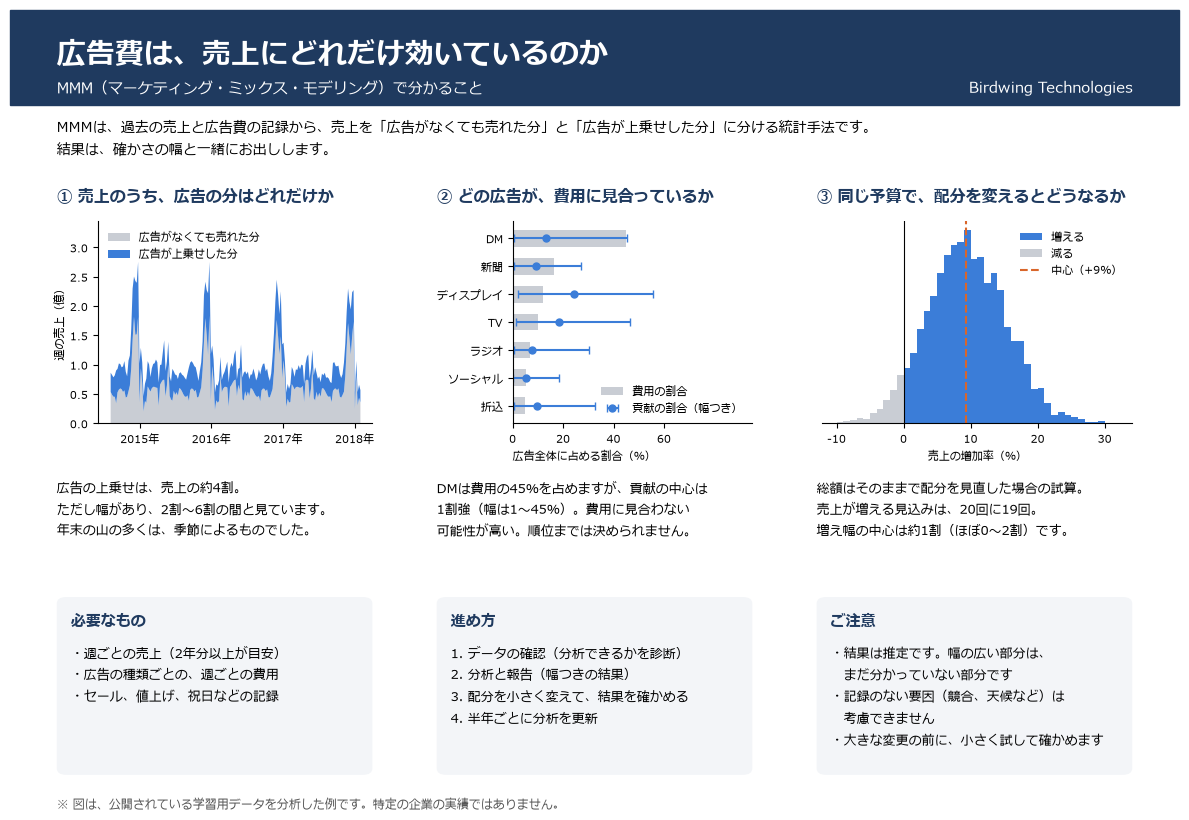

In [10]:
MY_TEXT = dict(TEXT)       # まず元の文章をコピーして、変えたいところだけ上書きする

MY_TEXT["title"] = "広告費は、売上にどれだけ効いているのか"
MY_TEXT["a1"] = TEXT["a1"]
MY_TEXT["a2"] = TEXT["a2"]
MY_TEXT["a3"] = TEXT["a3"]
MY_TEXT["need"] = TEXT["need"]
MY_TEXT["step"] = TEXT["step"]
MY_TEXT["note"] = TEXT["note"]

fig = make_onepager(MY_TEXT, OUT_DIR / "mmm_onepager_my.png")

> **PowerPoint で使うには**：保存された画像（PNG）を、スライドにそのまま貼りつけます。A4横の比率で作ってあります。
> 文字をあとから PowerPoint 上で直したい場合は、図だけを貼り、文章は PowerPoint のテキストボックスで書くほうが楽です。

## 8. データが少ない会社で使うときに

資料を見せると、「うちのデータでもできますか」と聞かれることがあります。自分の会社で導入を考えるときにも、最初に出てくる問いです。正直に答えられるように、目安を整理しておきます。

> ここに書くのは本家のケーススタディにはない内容で、この教材の結果と一般的な考え方から整理した**目安**です。実際のデータで確かめながら直していく前提で読んでください。

### 8-1. この教材のデータで分かったこと

この教材のデータは、**183週（3年半）・7チャネル**でした。それでも、次のような結果でした。

- 広告全体の貢献は「売上の2割〜6割」と、幅が3倍
- ROAS の上位3チャネルの順位は決められない
- adstock や頭打ちの曲がり方（α、λ）は、ほぼ分析前の想定のまま

つまり、**これだけのデータがあっても、細かいことまでは分かりません**。データがもっと少なければ、分かることはさらに減ります。

### 8-2. 向いている場合・向いていない場合（目安）

| | 向いている | 向いていない |
|---|---|---|
| **データの細かさ** | 週ごと（または日ごと）の売上がある | 月ごとの売上しかない（2年で24点。推定するパラメータの数より少なくなる） |
| **期間** | 2年以上（季節を2回以上見られる） | 1年未満（季節と広告の区別がつかない） |
| **広告の記録** | 種類ごと・週ごとの費用が残っている | 「年間いくら」しか分からない |
| **広告の動き** | 出した週と出さなかった週、多い週と少ない週がある | 毎週ほぼ同じ額（効果を見分ける手がかりがない） |
| **広告の種類** | 2〜5種類程度に、ある程度まとまった額を出している | 少額を多くの種類に分散している |

### 8-3. 向いていないときに、代わりにできること

MMMが向いていないと分かることも、価値のある結論です。その場合は、次のことから始めます。

1. **記録を始める**。週ごとの売上、広告の種類ごとの費用と実施日、セールや値上げの日付。1〜2年後に分析できるようになります
2. **小さな実験をする**。ある地域だけチラシを止める、ある週だけ広告を増やす。前後や地域間で比べます。データが少ない会社には、MMMより確かな答えが出ることがあります
3. **直接測れるものは直接測る**。クーポンコード、専用の電話番号、「何を見て来店しましたか」の質問

**言い方の例**

- ❌「MMMで、どの広告が効いているか分かります」
- ✅「まずデータを見て、どこまで分かりそうかを確かめます。分析に向かない場合は、記録の取り方を整えて、小さく試すところから始めます」

## 9. 小課題

自分の答えを考えてから「答えを見る」を開いてください。

**課題1**　資料を見た経営層に「細かい話はいいから、結局どの広告が一番効いているのか、一言で教えてほしい」と言われました。3章の表を見て、どう答えますか。

<details>
<summary>答えを見る</summary>

「一番」は、今回のデータでは決められません。正直にそう答えたうえで、言えることを伝えます。

- ROAS が一番高い確率は、折込 約31%、ディスプレイ 約29%、TV 約22%。3つのどれかである確率は合わせて約8割ですが、その中の順位は分かりません
- 一方で、**DM は費用の割に貢献が小さい**（約97%）、**追加の予算は DM より TV・折込に回したほうが効く**（約9割）は言えます

答え方の例：「一番を1つに決めることはできませんでした。ただ、折込・ディスプレイ・TV の3つが上位で、DM は費用の割に貢献が小さい、というところまでは高い確かさで言えます。ですので、DM の一部をこの3つに移すことをお勧めします」

「分かりません」で終わらせず、「ここまでは分かっている。だからこう動ける」まで言うのがポイントです。

</details>

**課題2**　資料の図②を見た経営層が「DM は効いていないのだから、来月からやめよう」と言いました。どう答えますか。

<details>
<summary>答えを見る</summary>

やめることは勧めません。理由は3つあります。

- **「費用の割に貢献が小さい」と「効いていない」は違う**。DM の貢献の中心は広告全体の1割強で、ゼロではありません。幅の上端では、費用の割合に近いところまであります
- **ゼロにしたときのことは、データにない**。DM を出さなかった週はほとんどなく、ゼロにしたときの売上はモデルの仮定に頼った予測になります。DM がほかの広告の効果を支えている可能性も、モデルは考慮していません
- **第7回の結論は「小さく動かす」**。まず2〜3割減らして、浮いた分を TV や折込に回し、売上を確かめる。予測どおりなら、さらに減らす

「減らす方向は合っている可能性が高いです。ただ、一度にやめるのではなく、段階的に減らして確かめましょう」と伝えます。

</details>

**課題3**　ある小売店が、MMMを使ってみたいと考えています。手元にあるのは、月ごとの売上が3年分。広告はチラシと Web 広告の2つで、費用は月ごとに分かります。この店に、MMMを勧めますか。

<details>
<summary>答えを見る</summary>

このままでは、MMMは勧めません。

- データは36点（3年 × 12か月）。季節（12か月）と2つの広告の効果を分けるには少なすぎます。この教材の183週でも、幅は広いままでした
- 月ごとにまとめると、「広告を出した週に売上が上がった」という手がかりが消えてしまいます

代わりに、次のことを勧めます。

- **週ごと・日ごとのデータが残っていないかを確かめる**。レジや会計ソフトには、日ごとの売上が残っていることが多い。チラシの配布日も分かれば、週ごとのデータを作り直せます
- **それが無理なら、小さな実験をする**。チラシを配る地域と配らない地域を分ける、Web 広告を2週間止めてみる、など
- **今後のために、記録の取り方を整える**

「分析できません」で終わらせず、「何があればできるか」「いまできることは何か」をセットで伝えます。

</details>

**課題4**　7章で作った自分の資料（`mmm_onepager_my.png`）を、MMMを知らない人に30秒見せたと想定してください。その人は、次の3つに答えられるでしょうか。答えられないものがあれば、文章を直してください。

1. これは何をする分析か
2. 結果はどれくらい信じてよいか
3. 頼むとしたら、何を用意すればよいか

<details>
<summary>考え方を見る</summary>

この課題に決まった答えはありません。確かめ方の例です。

- 実際に、家族や同僚に30秒だけ見せて、3つを聞いてみる
- タイトルと ①②③ の見出しだけを読んで、話の筋が通るかを確かめる
- 文章を声に出して読み、言いにくいところ、説明を足したくなるところを直す

資料は「読めば分かる」ではなく「見れば分かる」を目指します。説明を足したくなったら、文章を増やすのではなく、言いたいことを減らします。

</details>

## 10. まとめ

**この回のまとめ**

- 分析結果は「言える」「方向なら言える」「言えない」に分けてから、資料にする
- 専門用語は使わない。数字は丸めて、必ず幅を添える
- 資料は「何が分かるか」「どれくらい信じてよいか」「何が必要か」に答える
- 学習用データの例であることを、資料の中に書く
- 「うちのデータでもできますか」には、まずデータを確かめるところから始めると答える。向かない場合に、代わりにできることを持っておく

**全8回のまとめ**

| | できるようになったこと |
|---|---|
| データを見る | 相関と効果の違い（交絡）を、データで説明できる |
| モデルを作る | adstock・saturation・事前分布の意味を理解し、事前予測チェックで想定を確かめられる |
| 推定する | 計算の診断（divergence、R-hat、ESS）と、事前と事後の比較ができる |
| 結果を読む | 貢献・ROAS・限界ROASを、幅つきで読める。手計算でモデルを再現できる |
| 確かめる | 見ていない期間で検証し、単純な予測と比べて評価できる |
| 提案する | 制約つきで予算を最適化し、配分案の確かさを添えて、段階的な進め方を提案できる |
| 伝える | 経営層向けに、1枚で説明できる |

**このあとの学習**

- **ケーススタディ2（上級編）**：本家の題名は「Funnel-Aware Modeling, ROAS Calibration, and Budget Planning」。広告どうしの関係（ある広告がほかの広告を後押しする）を考えたモデル、実験結果を使った ROAS の補正、予算の計画を扱います。この教材でくり返し出てきた「最後は実験で確かめる」を、モデルに取り込む方法です
- **自分のデータで試す**：公開データや自分で作ったデータで、第3回〜第7回の流れを一通りやり直すと、理解が定着します

おつかれさまでした。